## Аппроксимация в ГП

Король Денис, 3 курс, 8А группа  
Вариант: 6

In [1]:
import numpy as np
from numpy.polynomial import legendre as L, chebyshev as C
from scipy.integrate import quad
import matplotlib.pyplot as plt
from scipy.special import zeta

np.set_printoptions(precision=6, suppress=True)

### Общее задание 1:
В гильбертовом пространстве L_2[−1, 1] приблизить функцию x(t) с точностью ε = 10^-4 многочленом. Для приближения использовать многочлены Лежандра.

### Индивидуальное задание 1.6:
x(t) = 2*|t| − t

eps = 1e-04
n = 554, eps_n = 9.952e-05
число коэффициентов: 555
ненулевых коэффициентов: 279

Первые 12 коэффициентов C_k (Лежандр):
  C_ 0 =  1.000000e+00
  C_ 1 = -1.000000e+00
  C_ 2 =  1.250000e+00
  C_ 3 =  3.330669e-16
  C_ 4 = -3.750000e-01
  C_ 5 =  1.249001e-16
  C_ 6 =  2.031250e-01
  C_ 7 = -2.914335e-16
  C_ 8 = -1.328125e-01
  C_ 9 = -3.573530e-16
  C_10 =  9.570313e-02
  C_11 = -1.526557e-16

Норма ||x||^2 = 3.333333
Сумма вкладов sum 2/(2k+1)*C_k^2 = 3.333333
Остаток (квадрат ошибки) = 9.903702e-09
Проверка: ||x||^2 - sum = 9.903702e-09


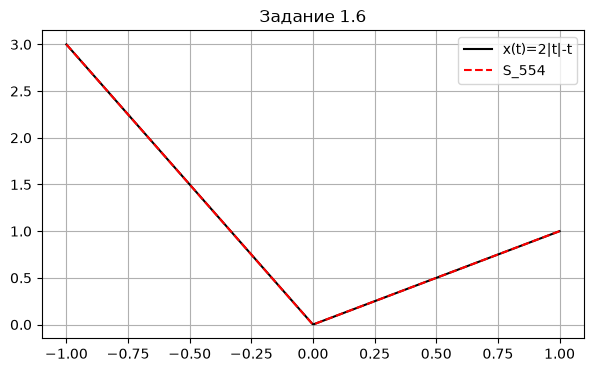

In [2]:
import numpy as np
from numpy.polynomial import legendre as L
from scipy.integrate import quad
import matplotlib.pyplot as plt

def x1(t):
    return 2*np.abs(t) - t

def int_Pk(k, a, b):
    c = np.zeros(k+1); c[k] = 1.0
    cint = L.legint(c)
    return L.legval(b, cint) - L.legval(a, cint)

def Ck_exact(k):
    def int_tPk(k, a, b):
        if k == 0:
            return int_Pk(1, a, b)
        return ((k+1)/(2*k+1))*int_Pk(k+1, a, b) + (k/(2*k+1))*int_Pk(k-1, a, b)
    I = -3*int_tPk(k, -1, 0) + 1*int_tPk(k, 0, 1)
    return (2*k+1)/2 * I

eps_target = 1e-4
norm2 = quad(lambda t: x1(t)**2, -1, 1)[0]

Ck = []
err2 = norm2
n = 0
while True:
    ck = Ck_exact(n)
    Ck.append(ck)
    err2 -= 2/(2*n+1) * ck**2
    err = np.sqrt(max(err2, 0.0))
    if err < eps_target:
        break
    n += 1

print(f"eps = {eps_target:.0e}")
print(f"n = {n}, eps_n = {err:.3e}")
print(f"число коэффициентов: {len(Ck)}")
nz = [(k, c) for k, c in enumerate(Ck) if abs(c) > 1e-12]
print(f"ненулевых коэффициентов: {len(nz)}")

def S1(t):
    return L.legval(t, Ck)

tt = np.linspace(-1, 1, 400)
plt.figure(figsize=(7,4))
plt.plot(tt, x1(tt), 'k-', label='x(t)=2|t|-t')
plt.plot(tt, S1(tt), 'r--', label=f'S_{n}')
plt.legend(); plt.grid(True); plt.title('Задание 1.6')

print("\nПервые 12 коэффициентов C_k (Лежандр):")
for k in range(min(12, len(Ck))):
    print(f"  C_{k:2d} = {Ck[k]: .6e}")

print(f"\nНорма ||x||^2 = {norm2:.6f}")
print(f"Сумма вкладов sum 2/(2k+1)*C_k^2 = {norm2 - err2:.6f}")
print(f"Остаток (квадрат ошибки) = {err2:.6e}")
print(f"Проверка: ||x||^2 - sum = {norm2 - (norm2 - err2):.6e}")

plt.show()

### Вывод по заданию 1.6
Функция x(t)=2|t|−t имеет излом в точке t=0 (не гладкая), поэтому коэффициенты Фурье по Лежандру убывают медленно (как O(1/k^3) в силу кусочной линейности), и для достижения ε=10^-4 требуется n=554 членов.

Отрезок ряда Фурье S_n(t) обладает экстремальным свойством: среди всех многочленов степени <= n он минимизирует норму ‖x−S_n‖ в L_2[−1,1], то есть даёт наилучшее среднеквадратичное приближение.

Достигнутая точность: ε_n = 9.95*10^-5 < ε = 10^-4

### Общее задание 2:
В гильбертовом пространстве L_2[−1, 1] заданную функцию x(t) приблизить многочленом степени не выше пятой. Для приближения использовать полиномы Чебышева первого рода.

### Индивидуальное задание 2.6:
x(t) = t * sin^2(t/2)

Среднеквадратичная погрешность (с весом): 7.260e-06
Коэффициенты Чебышева C_0..C_5:
  C_0 =  8.881784e-18
  C_1 =  1.748529e-01
  C_2 =  3.552714e-17
  C_3 =  5.621342e-02
  C_4 =  3.441691e-17
  C_5 = -1.227850e-03


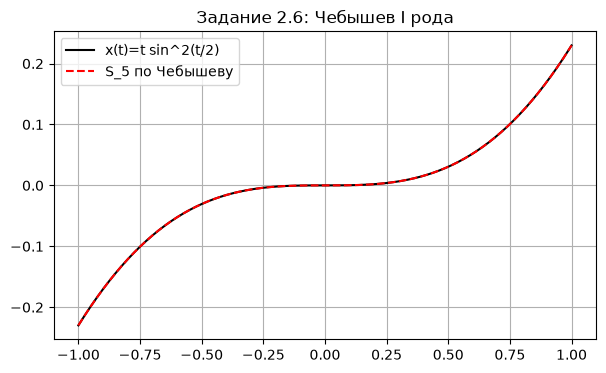

In [3]:
def x2(t):
    return t*np.sin(t/2)**2

Nq = 200
j = np.arange(1, Nq+1)
theta = (2*j-1)*np.pi/(2*Nq)
tj = np.cos(theta)

def cheb_T(k, t):
    c = np.zeros(k+1); c[k] = 1.0
    return C.chebval(t, c)

C0 = np.mean(x2(tj))
Ck_cheb = [C0]
for k in range(1, 6):
    Ck_cheb.append(2*np.mean(x2(tj)*cheb_T(k, tj)))

def S2(t):
    return sum(Ck_cheb[k]*cheb_T(k, t) for k in range(6))

num = quad(lambda t: (x2(t)-S2(t))**2/np.sqrt(1-t**2), -1, 1, limit=200)[0]
den = quad(lambda t: 1/np.sqrt(1-t**2), -1, 1)[0]
eps_L2w = np.sqrt(num/den)
print(f"Среднеквадратичная погрешность (с весом): {eps_L2w:.3e}")

tt = np.linspace(-1, 1, 400)
plt.figure(figsize=(7,4))
plt.plot(tt, x2(tt), 'k-', label='x(t)=t sin^2(t/2)')
plt.plot(tt, S2(tt), 'r--', label='S_5 по Чебышеву')
plt.legend(); plt.grid(True); plt.title('Задание 2.6: Чебышев I рода')

print("Коэффициенты Чебышева C_0..C_5:")
for k, c in enumerate(Ck_cheb):
    print(f"  C_{k} = {c: .6e}")

plt.show()

### Вывод по заданию 2.6
Функция x(t)=t*sin^2(t/2) бесконечно дифференцируема на [−1,1], поэтому её коэффициенты Чебышева убывают сверхстепенным образом (быстрее любой степени 1/k). Уже многочлен степени 5 даёт отличное приближение со среднеквадратичной (с весом (1−t^2)^{-1/2}) погрешностью ≈ 7.26·10^-6.

Коэффициенты вычислены через квадратуру Гаусса–Чебышева на 200 узлах.

### Общее задание 3:
В гильбертовом пространстве L_2[−п, п] приблизить функцию x(t) с точностью ε = 10^-2 тригонометрическим многочленом.

### Индивидуальное задание 3.6:
x(t) = 2t − t^2

Требуемое n = 502655
d_(n-1)² = 1.0000e-04   (≥ ε²)
d_n²     = 1.0000e-04   (< ε²)
d_n      = 1.0000e-02

Формула тригонометрического многочлена:
p_n(t) = -3.289868 + Σ_{k=1}^{502655} [ 4(-1)^(k+1)/k² · cos(kt) + 4(-1)^(k+1)/k · sin(kt) ]

Первые 10 коэффициентов тригонометрического ряда:
  a_0/2 = -3.289868
  k= 1:  a_k =  4.000000e+00,  b_k =  4.000000e+00
  k= 2:  a_k = -1.000000e+00,  b_k = -2.000000e+00
  k= 3:  a_k =  4.444444e-01,  b_k =  1.333333e+00
  k= 4:  a_k = -2.500000e-01,  b_k = -1.000000e+00
  k= 5:  a_k =  1.600000e-01,  b_k =  8.000000e-01
  k= 6:  a_k = -1.111111e-01,  b_k = -6.666667e-01
  k= 7:  a_k =  8.163265e-02,  b_k =  5.714286e-01
  k= 8:  a_k = -6.250000e-02,  b_k = -5.000000e-01
  k= 9:  a_k =  4.938272e-02,  b_k =  4.444444e-01
  k=10:  a_k = -4.000000e-02,  b_k = -4.000000e-01


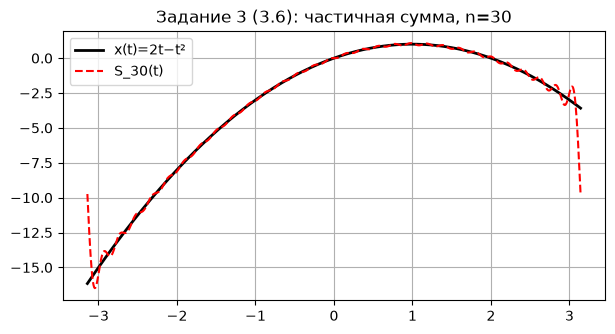

In [4]:
eps3 = 1e-2

a0 = -2*np.pi**2/3

n_cap = 2_000_000
karr = np.arange(1, n_cap+1, dtype=float)
cs2 = np.cumsum(1.0/karr**2)
cs4 = np.cumsum(1.0/karr**4)
d2_arr = 16*np.pi*((zeta(2) - cs2) + (zeta(4) - cs4))

mask = d2_arr < eps3**2
n_req3 = int(np.argmax(mask)) + 1
print(f"Требуемое n = {n_req3}")
print(f"d_(n-1)² = {d2_arr[n_req3-2]:.4e}   (≥ ε²)")
print(f"d_n²     = {d2_arr[n_req3-1]:.4e}   (< ε²)")
print(f"d_n      = {np.sqrt(d2_arr[n_req3-1]):.4e}")

print("\nФормула тригонометрического многочлена:")
print(f"p_n(t) = {a0/2:.6f} + Σ_{{k=1}}^{{{n_req3}}} [ "
      "4(-1)^(k+1)/k² · cos(kt) + 4(-1)^(k+1)/k · sin(kt) ]")

n_vis = 30
tt = np.linspace(-np.pi, np.pi, 800)
p_vis = a0/2 + sum(4*(-1)**(k+1)/k**2*np.cos(k*tt) + 4*(-1)**(k+1)/k*np.sin(k*tt)
                   for k in range(1, n_vis+1))
x_vis = 2*tt - tt**2
plt.figure(figsize=(7,3.5))
plt.plot(tt, x_vis, 'k-', lw=2, label='x(t)=2t−t²')
plt.plot(tt, p_vis, 'r--', label=f'S_{n_vis}(t)')
plt.legend(); plt.grid(True)
plt.title(f'Задание 3 (3.6): частичная сумма, n={n_vis}')

print("\nПервые 10 коэффициентов тригонометрического ряда:")
print(f"  a_0/2 = {a0/2:.6f}")
for k in range(1, 11):
    ak = 4*(-1)**(k+1)/k**2
    bk = 4*(-1)**(k+1)/k
    print(f"  k={k:2d}:  a_k = {ak: .6e},  b_k = {bk: .6e}")

plt.show()

### Вывод по заданию 3.6
Функция x(t) = 2t - t^2 не является периодической с периодом 2*п. На концах отрезка [-п, п] её значения не совпадают: x(-п) = -2*п - п^2, x(п) = 2*п - п^2. Поэтому при продолжении функции на всю ось получается разрыв, и ряд Фурье сходится медленно.

Коэффициенты убывают так: a_k ~ 1/k^2, b_k ~ 1/k. Чтобы получить точность 10^-2, понадобилось n = 502655 членов ряда. Это очень много и показывает, что тригонометрический ряд плохо подходит для непериодических функций.

Ошибку приближения считал по формуле Парсеваля:
d_n^2 = ||x||^2 - pi*(a_0^2/2 + сумма(a_k^2 + b_k^2))

### Общее задание 4:
В гильбертовом пространстве L_2[−1, 1] сравнить аппроксимацию бесконечно дифференцируемой функции  
x(t) = A_1*cos(w_1*t) + A_2*sin(w_2*t)  
тригонометрическим многочленом и многочленами Чебышева первого рода, используя N = 16, вычислив абсолютную погрешность.

### Индивидуальное задание 4.6:
A_1 = 1, A_2= 2, w_1 = 3, w_2 = 5

Сравнение при N=16:
  Тригонометрический: max|err| = 1.923e+00,  L2 = 3.015e-01
  Чебышев 1 рода:     max|err| = 4.698e-08,  L2 = 4.639e-08

Первые коэффициенты тригонометрического ряда (a_k, b_k):
  k=1: a_k =  9.7368e-01,  b_k =  7.9642e-01
  k=2: a_k = -2.7781e-02,  b_k =  1.6646e+00
  k=3: a_k =  1.0607e-02,  b_k = -5.6639e-01
  k=4: a_k = -5.6860e-03,  b_k =  3.6265e-01
  k=5: a_k =  3.5615e-03,  b_k = -2.7172e-01

Первые коэффициенты Чебышева C_k:
  C_0 = -2.6005e-01
  C_1 = -1.3103e+00
  C_2 = -9.7218e-01
  C_3 = -1.4593e+00
  C_4 =  2.6407e-01
  C_5 =  1.0446e+00

Отношение max-ошибок (триг./Чебыш.) = 4.09e+07
Отношение L2-ошибок  (триг./Чебыш.) = 6.50e+06


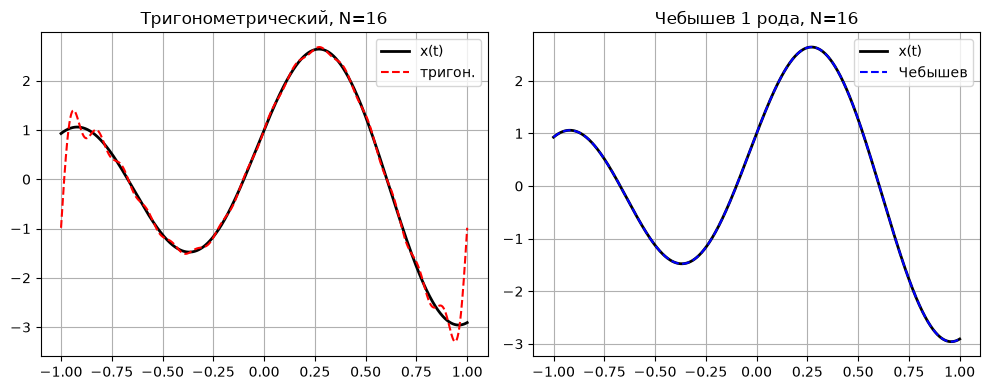

In [5]:
A1, A2, w1, w2 = 1.0, 2.0, 3.0, 5.0
def x4(t):
    return A1*np.cos(w1*t) + A2*np.sin(w2*t)

N = 16
a, b = -1.0, 1.0

a0 = quad(x4, a, b, limit=200)[0]
ak, bk = [], []
for k in range(1, N+1):
    ak.append(quad(lambda t: x4(t)*np.cos(k*np.pi*t), a, b, limit=200)[0])
    bk.append(quad(lambda t: x4(t)*np.sin(k*np.pi*t), a, b, limit=200)[0])

def S4_trig(t):
    s = a0/2
    for k in range(1, N+1):
        s += ak[k-1]*np.cos(k*np.pi*t) + bk[k-1]*np.sin(k*np.pi*t)
    return s

Nq = 400
j = np.arange(1, Nq+1)
theta = (2*j-1)*np.pi/(2*Nq)
tj = np.cos(theta)

def cheb_T(k, t):
    c = np.zeros(k+1); c[k] = 1.0
    return C.chebval(t, c)

C0 = np.mean(x4(tj))
Ck = [C0]
for k in range(1, N+1):
    Ck.append(2*np.mean(x4(tj)*cheb_T(k, tj)))

def S4_cheb(t):
    return sum(Ck[k]*cheb_T(k, t) for k in range(N+1))

tt = np.linspace(a, b, 5000)
err_trig_max = np.max(np.abs(x4(tt) - S4_trig(tt)))
err_cheb_max = np.max(np.abs(x4(tt) - S4_cheb(tt)))

L2_trig = np.sqrt(np.trapezoid((x4(tt)-S4_trig(tt))**2, tt))
L2_cheb = np.sqrt(np.trapezoid((x4(tt)-S4_cheb(tt))**2, tt))

print("Сравнение при N=16:")
print(f"  Тригонометрический: max|err| = {err_trig_max:.3e},  L2 = {L2_trig:.3e}")
print(f"  Чебышев 1 рода:     max|err| = {err_cheb_max:.3e},  L2 = {L2_cheb:.3e}")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(tt, x4(tt), 'k-', lw=2, label='x(t)')
plt.plot(tt, S4_trig(tt), 'r--', label='тригон.')
plt.legend(); plt.grid(True); plt.title('Тригонометрический, N=16')

plt.subplot(1,2,2)
plt.plot(tt, x4(tt), 'k-', lw=2, label='x(t)')
plt.plot(tt, S4_cheb(tt), 'b--', label='Чебышев')
plt.legend(); plt.grid(True); plt.title('Чебышев 1 рода, N=16')

print("\nПервые коэффициенты тригонометрического ряда (a_k, b_k):")
for k in range(1, 6):
    print(f"  k={k}: a_k = {ak[k-1]: .4e},  b_k = {bk[k-1]: .4e}")

print("\nПервые коэффициенты Чебышева C_k:")
for k in range(6):
    print(f"  C_{k} = {Ck[k]: .4e}")

print(f"\nОтношение max-ошибок (триг./Чебыш.) = {err_trig_max/err_cheb_max:.2e}")
print(f"Отношение L2-ошибок  (триг./Чебыш.) = {L2_trig/L2_cheb:.2e}")

plt.tight_layout(); plt.show()

### Вывод по заданию 4.6
Сравнил два способа приблизить гладкую функцию x(t) = cos(3t) + 2sin(5t) на отрезке [-1, 1] при N = 16.

Тригонометрический многочлен дал ошибку около 1.92 (по максимуму) и 0.30 (в среднем квадратичном).
Многочлен Чебышева дал ошибку порядка 5*10^-8, то есть почти в сто миллионов раз меньше